In [209]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from calc_sofa import calc_sofa

# Demographics

In [70]:
demographics = pd.read_csv('admissions_demographics.csv', index_col=0)

,SexDSC,PatientRaceDSC,EthnicGroupDSC,Age,Hours_to_mortality,Days_to_mortality,Months_to_mortality,Years_to_mortality,Time_to_death,LOS_date_time,LOS_date_based
Admission,,,,,,,,,,,
0,Male,White,Not Hispanic,79,NaN,NaN,NaN,NaN,NaN,19 days 13:38:00,19 days 00:00:00
1,Male,White,Not Hispanic,63,NaN,NaN,NaN,NaN,NaN,6 days 07:22:00,6 days 00:00:00
2,Female,White,Not Hispanic,75,8.0,0.0,9.0,3.0,1370 days 08:14:00,10 days 00:35:00,10 days 00:00:00
3,Female,White,Not Hispanic,78,8.0,20.0,0.0,0.0,20 days 08:53:00,20 days 15:48:00,21 days 00:00:00
4,Male,White,Not Hispanic,21,NaN,NaN,NaN,NaN,NaN,23 days 21:37:00,24 days 00:00:00


In [71]:
demographics['Time_to_death'] = pd.to_timedelta(demographics['Time_to_death'])
demographics['LOS_date_time'] = pd.to_timedelta(demographics['LOS_date_time'])
demographics['LOS_date_based'] = pd.to_timedelta(demographics['LOS_date_based'])

In [96]:
demographics.head()

,SexDSC,PatientRaceDSC,EthnicGroupDSC,Age,Hours_to_mortality,Days_to_mortality,Months_to_mortality,Years_to_mortality,Time_to_death,LOS_date_time,LOS_date_based
Admission,,,,,,,,,,,
0,Male,White,Not Hispanic,79,NaN,NaN,NaN,NaN,NaT,19 days 13:38:00,19 days
1,Male,White,Not Hispanic,63,NaN,NaN,NaN,NaN,NaT,6 days 07:22:00,6 days
2,Female,White,Not Hispanic,75,8.0,0.0,9.0,3.0,1370 days 08:14:00,10 days 00:35:00,10 days
3,Female,White,Not Hispanic,78,8.0,20.0,0.0,0.0,20 days 08:53:00,20 days 15:48:00,21 days
4,Male,White,Not Hispanic,21,NaN,NaN,NaN,NaN,NaT,23 days 21:37:00,24 days


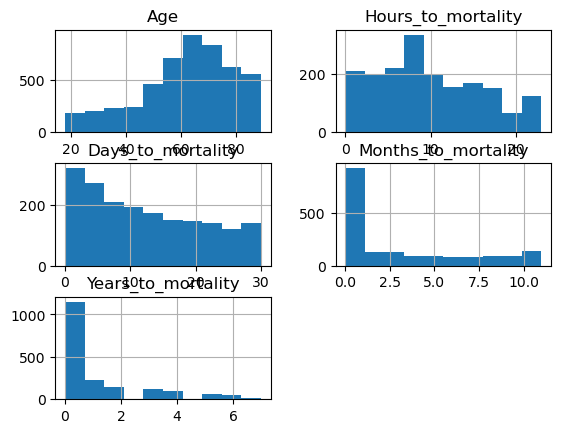

In [72]:
demographics.hist()
plt.show()

# Diagnostics

In [104]:
def generic_load_diagnostic_data(filename):
    data = pd.read_csv(filename+'.csv')
    data['Time_after_admission'] = pd.to_timedelta(data['Time_after_admission'])
    data = data.set_index(['Admission', 'Time_after_admission'])
    return data

In [247]:
filenames = [
    'bilirubin', 
    'bp_admission', 
    'creatinine', 
    'dobu_admission', 
    'dopamine', 
    'epinephrine', 
    'gcs_admission', 
    'mech_vent_cpap_admission',
    'norepinephrine',
    'pao2fio2',
    'platelets',
    'uo_admission',
]

feature_info = dict()
feature_info['bilirubin'] = {'numeric': ['Total_Bilirubin_mg_per_dL'], 'sofa_groupby': 'max'}
feature_info['bp_admission'] = {'numeric': ['SBP', 'DBP', 'MAP'], 'sofa_groupby': 'min'}
feature_info['creatinine'] =  {'numeric': ['Creatinine_mg_per_dL'], 'sofa_groupby': 'max'}
feature_info['dobu_admission'] =  {'numeric': ['Dobutamine_any_dose'], 'sofa_groupby': 'first'}
feature_info['dopamine'] =  {'numeric': ['Dopamine_μg_kg_min'], 'sofa_groupby': 'max'}
feature_info['epinephrine'] =  {'numeric': ['Epinephrine_μg_kg_min'], 'sofa_groupby': 'max'}
feature_info['gcs_admission'] =  {'numeric': ['GCS'], 'sofa_groupby': 'min'}
feature_info['mech_vent_cpap_admission'] =  {'numeric': ['mech_vent_cpap'], 'sofa_groupby': 'first'}
feature_info['norepinephrine'] =  {'numeric': ['Norepinephrine_μg_kg_min'], 'sofa_groupby': 'max'}
feature_info['pao2fio2'] =  {'numeric': ['PaO2', 'FiO2', 'PaO2_FiO2'], 'sofa_groupby': 'min'}
feature_info['platelets'] =  {'numeric': ['Platelets_10_3_per_ml'], 'sofa_groupby': 'min'}
feature_info['uo_admission'] =  {'numeric': ['Urine_output_mL'], 'sofa_groupby': 'sum'}

SOFA_FEATURES = ['Total_Bilirubin_mg_per_dL', 'MAP', 'Creatinine_mg_per_dL', 'Dobutamine_any_dose', 'Dopamine_μg_kg_min', 'Epinephrine_μg_kg_min', 'GCS', 'mech_vent_cpap', 'Norepinephrine_μg_kg_min', 'PaO2_FiO2', 'Platelets_10_3_per_ml', 'Urine_output_mL']

In [248]:
diagnostic_dfs = {filename: generic_load_diagnostic_data(filename) for filename in filenames}

In [249]:
full_patient_df = pd.DataFrame(index=demographics.index)
for df_name in diagnostic_dfs:
    # select only numeric features from each diagnostic dataframe
    diagnostic = diagnostic_dfs[df_name].loc[:, feature_info[df_name]['numeric']]

    # grab the first day of a patient's stay
    diagnostic = diagnostic.loc[diagnostic.index.get_level_values(1) < pd.Timedelta('1 days')]

    # aggregate on the patient level using the aggregation function specified in feature_info
    diagnostic = diagnostic.groupby(level=0).agg(feature_info[df_name]['sofa_groupby'])

    full_patient_df = full_patient_df.merge(diagnostic, left_index=True, right_index=True, how='outer')

med_amt_cols = ["Dopamine_μg_kg_min", "Epinephrine_μg_kg_min", "Norepinephrine_μg_kg_min"]
full_patient_df.loc[full_patient_df['mech_vent_cpap'] != 1, 'mech_vent_cpap'] = 0
full_patient_df.loc[full_patient_df['Dobutamine_any_dose'] != 1, 'Dobutamine_any_dose'] = 0

In [250]:
# get rid of top or bottom percentiles for some columns, b/c they're probably not real.
discard_99th = [
    "PaO2_FiO2", "Total_Bilirubin_mg_per_dL", "Platelets_10_3_per_ml", "Creatinine_mg_per_dL", "Urine_output_mL",
    "Dopamine_μg_kg_min", "Epinephrine_μg_kg_min", "Norepinephrine_μg_kg_min"
]
discard_1st = ["PaO2_FiO2", "Platelets_10_3_per_ml", "Creatinine_mg_per_dL", "Urine_output_mL"]
top_percents = full_patient_df[discard_99th].quantile(0.99)
bott_percents = full_patient_df[discard_1st].quantile(0.01)

full_patient_df.loc[:, discard_99th] = full_patient_df[discard_99th].where(full_patient_df[discard_99th] <= top_percents, np.nan)
full_patient_df.loc[:, discard_1st] = full_patient_df[discard_1st].where(full_patient_df[discard_1st] >= bott_percents, np.nan)

# replace nan with 0 for these meds

fill_na_cols = ["Dobutamine_any_dose", "Dopamine_μg_kg_min", "Epinephrine_μg_kg_min", "Norepinephrine_μg_kg_min"]
full_patient_df.loc[:, fill_na_cols] = full_patient_df[fill_na_cols].fillna(0)

In [257]:
full_patient_df = full_patient_df.loc[:, SOFA_FEATURES].dropna(axis=0)
real_sofas = full_patient_df.apply(calc_sofa, axis=1)

In [259]:
real_sofas

Admission
13      11.0
16       9.0
17       8.0
21      14.0
22      12.0
        ... 
4964     8.0
4971     5.0
4972    11.0
4987     7.0
4988     5.0
Length: 422, dtype: float64

In [260]:
full_patient_df

,Total_Bilirubin_mg_per_dL,MAP,Creatinine_mg_per_dL,Dobutamine_any_dose,Dopamine_μg_kg_min,Epinephrine_μg_kg_min,GCS,mech_vent_cpap,Norepinephrine_μg_kg_min,PaO2_FiO2,Platelets_10_3_per_ml,Urine_output_mL
Admission,,,,,,,,,,,,
13,0.5,55.666667,1.24,0.0,0.0,0.0,6.0,1.0,75.0,210.000000,125.0,519.0
16,0.5,60.000000,2.53,0.0,0.0,0.0,5.0,1.0,0.0,290.000000,199.0,80.0
17,0.2,55.333333,4.93,0.0,0.0,0.0,8.0,1.0,0.0,326.666667,238.0,175.0
21,0.6,51.666667,2.68,0.0,0.0,0.0,5.0,1.0,37.5,152.500000,141.0,245.0
22,0.3,56.666667,2.81,0.0,0.0,0.0,7.0,1.0,13.5,257.500000,112.0,125.0
...,...,...,...,...,...,...,...,...,...,...,...,...
4964,0.7,61.666667,1.04,0.0,0.0,0.0,7.0,1.0,0.0,276.000000,96.0,1600.0
4971,0.5,91.333333,0.91,0.0,0.0,0.0,6.0,1.0,0.0,270.000000,249.0,2850.0
4972,0.8,40.333333,1.25,0.0,0.0,0.0,3.0,1.0,262.5,454.000000,54.0,530.0


In [266]:
sum(demographics['Time_to_death'] < demographics['LOS_date_time'])

649